# 04 – Validation Results and Catalog Summary

This notebook summarizes the **executed outputs from corrected Notebook 03**.

It compares random row-level cross-validation with host-star-grouped cross-validation, reports the descriptive confirmed-catalog fraction, and visualizes the validation metrics.

**Important interpretation:** the confirmed-catalog fraction is a descriptive statistic for the filtered KOI catalog. It is **not** a completeness-corrected astrophysical occurrence rate. This notebook does not calculate a model-screened occurrence-rate correction or claim a before/after change in the intrinsic occurrence rate.

The values below are copied from the executed Notebook 03 results supplied for this analysis. If Notebook 03 is rerun and its outputs change, update the values here from its exported CSV files.

In [1]:
# CELL 1 — Imports and results from the executed Notebook 03

import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Results recorded by executed Notebook 03.
# Source: 03_validation_metrics.csv and 03_catalog_fraction_summary.csv
N_CATALOG_ROWS = 4249
N_CATALOG_STARS = 3517
N_CONFIRMED_HOST_STARS = 1463
BASELINE_CATALOG_FRACTION = 0.41597953

N_LABELED_ROWS = 3195
N_LABELED_HOST_STARS = 2654
N_FALSE_POSITIVE_ROWS = 1229
N_CONFIRMED_ROWS = 1966

RANDOM_FOLD_COUNTS = [639, 639, 639, 639, 639]
GROUPED_FOLD_COUNTS = [628, 650, 660, 628, 629]

features = [
    "koi_period", "koi_time0bk", "koi_impact", "koi_duration",
    "koi_depth", "koi_prad", "koi_teq", "koi_insol",
    "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"
]

validation = pd.DataFrame([
    {
        "validation": "Random row-level CV",
        "ROC_AUC": 0.926194,
        "average_precision": 0.944526,
        "balanced_accuracy": 0.847124,
        "Brier_score_lower_is_better": 0.103644,
        "precision_at_fixed_threshold": 0.867146,
        "recall_at_fixed_threshold": 0.919634,
        "F1_at_fixed_threshold": 0.892619,
        "threshold": 0.50
    },
    {
        "validation": "Host-star grouped CV",
        "ROC_AUC": 0.923559,
        "average_precision": 0.943764,
        "balanced_accuracy": 0.845038,
        "Brier_score_lower_is_better": 0.105693,
        "precision_at_fixed_threshold": 0.867569,
        "recall_at_fixed_threshold": 0.913021,
        "F1_at_fixed_threshold": 0.889715,
        "threshold": 0.50
    }
])

catalog_summary = pd.DataFrame([{
    "filtered_catalog_rows": N_CATALOG_ROWS,
    "unique_stars_in_filtered_catalog": N_CATALOG_STARS,
    "stars_with_at_least_one_confirmed_entry": N_CONFIRMED_HOST_STARS,
    "baseline_confirmed_catalog_fraction": BASELINE_CATALOG_FRACTION,
    "baseline_confirmed_catalog_fraction_percent": 100 * BASELINE_CATALOG_FRACTION,
    "resolved_labeled_rows": N_LABELED_ROWS,
    "unique_host_stars_in_labeled_data": N_LABELED_HOST_STARS,
    "false_positive_rows": N_FALSE_POSITIVE_ROWS,
    "confirmed_rows": N_CONFIRMED_ROWS
}])

print("=== CATALOG SUMMARY ===")
display(catalog_summary)

print("\n=== POOLED OUT-OF-FOLD VALIDATION METRICS ===")
display(validation)

print("\nFeatures used in Notebook 03:")
for feature in features:
    print(" -", feature)


=== CATALOG SUMMARY ===


,filtered_catalog_rows,unique_stars_in_filtered_catalog,stars_with_at_least_one_confirmed_entry,baseline_confirmed_catalog_fraction,baseline_confirmed_catalog_fraction_percent,resolved_labeled_rows,unique_host_stars_in_labeled_data,false_positive_rows,confirmed_rows
0,4249,3517,1463,0.41598,41.597953,3195,2654,1229,1966



=== POOLED OUT-OF-FOLD VALIDATION METRICS ===


,validation,ROC_AUC,average_precision,balanced_accuracy,Brier_score_lower_is_better,precision_at_fixed_threshold,recall_at_fixed_threshold,F1_at_fixed_threshold,threshold
0,Random row-level CV,0.926194,0.944526,0.847124,0.103644,0.867146,0.919634,0.892619,0.5
1,Host-star grouped CV,0.923559,0.943764,0.845038,0.105693,0.867569,0.913021,0.889715,0.5



Features used in Notebook 03:
 - koi_period
 - koi_time0bk
 - koi_impact
 - koi_duration
 - koi_depth
 - koi_prad
 - koi_teq
 - koi_insol
 - koi_steff
 - koi_slogg
 - koi_srad
 - koi_kepmag


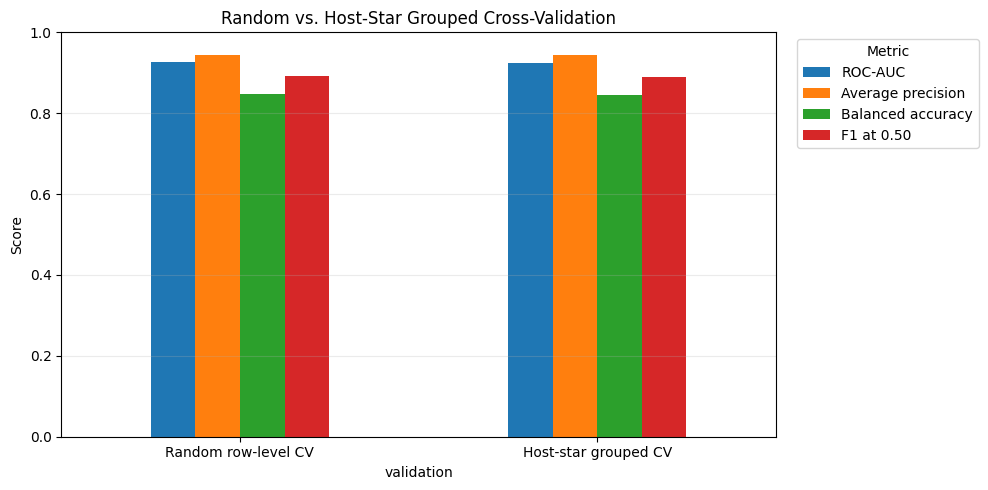

In [2]:
# CELL 2 — Plot the validation metrics

metrics_to_plot = [
    "ROC_AUC",
    "average_precision",
    "balanced_accuracy",
    "F1_at_fixed_threshold"
]

ax = validation.set_index("validation")[metrics_to_plot].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)
ax.set_ylabel("Score")
ax.set_title("Random vs. Host-Star Grouped Cross-Validation")
ax.legend(
    title="Metric",
    labels=["ROC-AUC", "Average precision", "Balanced accuracy", "F1 at 0.50"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


In [3]:
# CELL 3 — Calculate grouped-minus-random metric differences

metric_columns = [
    "ROC_AUC",
    "average_precision",
    "balanced_accuracy",
    "Brier_score_lower_is_better",
    "precision_at_fixed_threshold",
    "recall_at_fixed_threshold",
    "F1_at_fixed_threshold"
]

random_row = validation.loc[
    validation["validation"] == "Random row-level CV"
].iloc[0]
grouped_row = validation.loc[
    validation["validation"] == "Host-star grouped CV"
].iloc[0]

differences = pd.DataFrame({
    "metric": metric_columns,
    "random_row_level": [random_row[m] for m in metric_columns],
    "host_star_grouped": [grouped_row[m] for m in metric_columns],
    "grouped_minus_random": [
        grouped_row[m] - random_row[m] for m in metric_columns
    ]
})

display(differences.style.format({
    "random_row_level": "{:.6f}",
    "host_star_grouped": "{:.6f}",
    "grouped_minus_random": "{:+.6f}"
}))

print(
    "\nInterpretation: the grouped and random validation metrics are similar "
    "in this run. The small differences should be reported as observed; "
    "do not claim that grouping caused a large performance change."
)


,metric,random_row_level,host_star_grouped,grouped_minus_random
0,ROC_AUC,0.926194,0.923559,-0.002635
1,average_precision,0.944526,0.943764,-0.000762
2,balanced_accuracy,0.847124,0.845038,-0.002086
3,Brier_score_lower_is_better,0.103644,0.105693,+0.002049
4,precision_at_fixed_threshold,0.867146,0.867569,+0.000423
5,recall_at_fixed_threshold,0.919634,0.913021,-0.006613
6,F1_at_fixed_threshold,0.892619,0.889715,-0.002904



Interpretation: the grouped and random validation metrics are similar in this run. The small differences should be reported as observed; do not claim that grouping caused a large performance change.


Filtered catalog rows: 4,249
Unique stars in filtered catalog: 3,517
Stars with at least one confirmed entry: 1,463
Descriptive confirmed-catalog fraction: 41.5980%

This is the descriptive fraction of stars represented in the filtered KOI catalog that have at least one confirmed entry. It is not corrected for detection completeness, transit geometry, or catalog selection effects, and therefore is not an intrinsic planet occurrence-rate estimate.


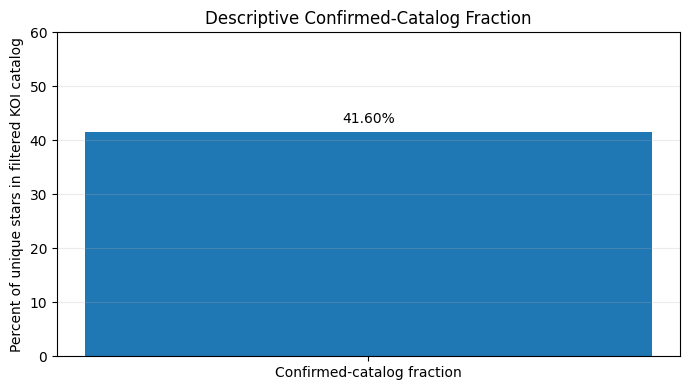

In [4]:
# CELL 4 — Report the descriptive catalog fraction

catalog_fraction_percent = 100 * BASELINE_CATALOG_FRACTION

print(f"Filtered catalog rows: {N_CATALOG_ROWS:,}")
print(f"Unique stars in filtered catalog: {N_CATALOG_STARS:,}")
print(f"Stars with at least one confirmed entry: {N_CONFIRMED_HOST_STARS:,}")
print(f"Descriptive confirmed-catalog fraction: {catalog_fraction_percent:.4f}%")

print(
    "\nThis is the descriptive fraction of stars represented in the filtered "
    "KOI catalog that have at least one confirmed entry. It is not corrected "
    "for detection completeness, transit geometry, or catalog selection "
    "effects, and therefore is not an intrinsic planet occurrence-rate estimate."
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    ["Confirmed-catalog fraction"],
    [catalog_fraction_percent]
)
ax.set_ylabel("Percent of unique stars in filtered KOI catalog")
ax.set_title("Descriptive Confirmed-Catalog Fraction")
ax.set_ylim(0, max(60, catalog_fraction_percent * 1.25))
ax.grid(axis="y", alpha=0.25)

for bar in ax.patches:
    value = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [5]:
# CELL 5 — Display fold sizes and class counts reported by Notebook 03

fold_summary = pd.DataFrame({
    "fold": [1, 2, 3, 4, 5],
    "random_row_level_test_rows": RANDOM_FOLD_COUNTS,
    "host_star_grouped_test_rows": GROUPED_FOLD_COUNTS
})
display(fold_summary)

class_counts = pd.Series(
    {
        "False positive (label 0)": N_FALSE_POSITIVE_ROWS,
        "Confirmed (label 1)": N_CONFIRMED_ROWS
    },
    name="resolved_labeled_rows"
)
display(class_counts.to_frame())

print(
    "\nNotebook 03 reported zero host-star overlap between training and test "
    "groups in each of the five grouped folds."
)


,fold,random_row_level_test_rows,host_star_grouped_test_rows
0,1,639,628
1,2,639,650
2,3,639,660
3,4,639,628
4,5,639,629


,resolved_labeled_rows
False positive (label 0),1229
Confirmed (label 1),1966



Notebook 03 reported zero host-star overlap between training and test groups in each of the five grouped folds.


In [6]:
# CELL 6 — Save Notebook 04 summary tables

# Kaggle writes these files to the notebook's working directory.
os.makedirs("/kaggle/working", exist_ok=True)

validation.to_csv(
    "/kaggle/working/04_validation_metrics_summary.csv",
    index=False
)
catalog_summary.to_csv(
    "/kaggle/working/04_catalog_summary.csv",
    index=False
)
differences.to_csv(
    "/kaggle/working/04_validation_metric_differences.csv",
    index=False
)
fold_summary.to_csv(
    "/kaggle/working/04_fold_summary.csv",
    index=False
)

print("Notebook 04 completed.")
print("Saved:")
print("- 04_validation_metrics_summary.csv")
print("- 04_catalog_summary.csv")
print("- 04_validation_metric_differences.csv")
print("- 04_fold_summary.csv")


Notebook 04 completed.
Saved:
- 04_validation_metrics_summary.csv
- 04_catalog_summary.csv
- 04_validation_metric_differences.csv
- 04_fold_summary.csv
